# Assignment 1 — Data Profiling (EDA) Report
## Bursa Malaysia Sector Stocks & Bank Negara OPR Decisions

**Course:** TTTC3213 Data Engineering · Universiti Kebangsaan Malaysia

| Name | Matric No. |
|---|---|
| RAVINRAJ A/L VASU | A212782 |
| CHARAN BAHADUR NEWAR A/L KARNA BAHADUR NEWAR| A211997 |
| ADAM BUKHARY BIN MOHAMMAD SHAHRUL NIZAM | A213606|
| MUHAMMAD SYAMIL BIN MOHD ZAIDI | A213608 |

> This notebook profiles the data for our capstone (Finance / FinTech domain). Its purpose is to **diagnose and fix data quality problems**, not to present investment insights.

## 1. Scenario

An investment firm wants to track how stocks in different Bursa Malaysia sectors (financial, property, consumer, plantation, utilities) behave before and after Bank Negara Malaysia's Overnight Policy Rate (OPR) announcements, so it can identify rate-sensitive sectors and adjust client portfolios faster.

**Why it fits the assignment:** the data is combined from three sources that do not line up cleanly. Stocks listed at different times leave **missing values**, trading suspensions and holidays leave **gaps**, ex-dividend days and market crashes (e.g. March 2020) produce **outliers**, Yahoo's sector labels **conflict** with Bursa's official classification, and the OPR table is published as text (`"3.25%"`, `"25 January 2018"`) that must be converted. The stock selection itself carries **sampling (survivorship) bias**.

**Questions we want the data to support:**
1. Which sectors show the largest price reaction in the days around an OPR change?
2. Do banking stocks and property stocks react in opposite directions to hikes vs cuts?
3. Is the data complete and reliable enough, per stock and per event, to answer 1–2 fairly?

## 2. Data Source

| Dataset | Source | URL | How obtained |
|---|---|---|---|
| Daily OHLCV prices, dividends and splits for 20 Bursa stocks + FBM KLCI index (`^KLSE`) | Yahoo Finance | https://finance.yahoo.com/quote/1155.KL | Python `yfinance` library (`Ticker.history`, `auto_adjust=False, actions=True`), 2018-01-01 to today |
| Yahoo's sector / industry label per stock | Yahoo Finance profile | https://finance.yahoo.com/quote/1155.KL/profile | `yfinance` `Ticker.info` |
| Official Bursa sector of each stock | Bursa Malaysia | https://www.bursamalaysia.com/market_information/equities_prices | Looked up manually and entered in the notebook as a reference table |
| OPR decision dates and rates | Bank Negara Malaysia Monetary Policy Statements | https://www.bnm.gov.my/monetary-stability/opr-decisions | Transcribed from the published statements, kept in the original text format |

Raw downloads are saved to `data/raw/` **before** any cleaning, so the notebook can be re-run offline and Yahoo outages do not break it. Cleaned output goes to `data/processed/` and charts to `figures/`.

**Terms of use:** `yfinance` uses Yahoo's public endpoints; the data is used for non-commercial academic purposes only and requests are throttled. No pages were scraped from Bursa or BNM; their values were read and entered by hand.

### How to run
```bash
pip install -r requirements.txt
jupyter notebook data_profiling.ipynb   # then: Kernel → Restart & Run All
```
The first run needs internet (≈1–2 minutes). Later runs read from `data/raw/`. Delete that folder to force a fresh download.

In [1]:
import os, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

RAW, PROC, FIG = Path("data/raw"), Path("data/processed"), Path("figures")
for p in (RAW, PROC, FIG):
    p.mkdir(parents=True, exist_ok=True)

START = "2018-01-01"
END = pd.Timestamp.today().strftime("%Y-%m-%d")
INDEX = "^KLSE"            # FBM KLCI benchmark
MAX_FFILL = 3              # longest gap (trading days) we are willing to forward-fill

# Official Bursa sector classification (entered manually from bursamalaysia.com)
STOCKS = {
    "1155.KL": ("Malayan Banking (Maybank)", "Financial Services"),
    "1295.KL": ("Public Bank",               "Financial Services"),
    "1023.KL": ("CIMB Group",                "Financial Services"),
    "1066.KL": ("RHB Bank",                  "Financial Services"),
    "5819.KL": ("Hong Leong Bank",           "Financial Services"),
    "8664.KL": ("SP Setia",                  "Property"),
    "5288.KL": ("Sime Darby Property",       "Property"),
    "8583.KL": ("Mah Sing Group",            "Property"),
    "8206.KL": ("Eco World Development",     "Property"),
    "5249.KL": ("IOI Properties",            "Property"),
    "4707.KL": ("Nestle Malaysia",           "Consumer Products & Services"),
    "7084.KL": ("QL Resources",              "Consumer Products & Services"),
    "5296.KL": ("MR D.I.Y. Group",           "Consumer Products & Services"),
    "5326.KL": ("99 Speed Mart Retail",      "Consumer Products & Services"),
    "1961.KL": ("IOI Corporation",           "Plantation"),
    "2445.KL": ("Kuala Lumpur Kepong",       "Plantation"),
    "5285.KL": ("SD Guthrie",                "Plantation"),
    "5347.KL": ("Tenaga Nasional",           "Utilities"),
    "6742.KL": ("YTL Power International",   "Utilities"),
    "6033.KL": ("Petronas Gas",              "Utilities"),
}
sector_map = (pd.DataFrame.from_dict(STOCKS, orient="index", columns=["company", "bursa_sector"])
                .rename_axis("Ticker").reset_index())
TICKERS = list(STOCKS) + [INDEX]
print(f"{len(STOCKS)} stocks + index, {START} → {END}")

20 stocks + index, 2018-01-01 → 2026-11-01


In [2]:
# --- Ingest prices (download once, then always read the raw file) -----------
PRICE_FILE = RAW / "prices_raw.csv"

def download_prices(tickers):
    import yfinance as yf
    frames, failed = [], []
    for t in tickers:
        try:
            h = yf.Ticker(t).history(start=START, end=END, auto_adjust=False, actions=True)
        except Exception as e:
            print(f"  {t}: error {e}")
            h = pd.DataFrame()
        if h.empty:
            failed.append(t)
            continue
        h = h.reset_index()
        h["Ticker"] = t
        frames.append(h)
        time.sleep(0.5)               # be polite to Yahoo
    print("Failed downloads:", failed or "none")
    return pd.concat(frames, ignore_index=True)

if not PRICE_FILE.exists():
    download_prices(TICKERS).to_csv(PRICE_FILE, index=False)

raw = pd.read_csv(PRICE_FILE)
print(raw.shape)
raw.head()

Failed downloads: none
(43083, 10)


,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Ticker
0,2018-01-02 00:00:00+08:00,9.65,9.68,9.59,9.66,5.398767,5284100,0.0,0.0,1155.KL
1,2018-01-03 00:00:00+08:00,9.66,9.78,9.66,9.78,5.465833,13946300,0.0,0.0,1155.KL
2,2018-01-04 00:00:00+08:00,9.78,9.82,9.78,9.80,5.477010,18711500,0.0,0.0,1155.KL
3,2018-01-05 00:00:00+08:00,9.80,9.82,9.79,9.80,5.477010,17266600,0.0,0.0,1155.KL
4,2018-01-08 00:00:00+08:00,9.80,9.85,9.79,9.85,5.504955,19238800,0.0,0.0,1155.KL


In [3]:
# --- Ingest Yahoo's own sector labels (to compare with Bursa's) -------------
INFO_FILE = RAW / "yahoo_info_raw.csv"

if not INFO_FILE.exists():
    import yfinance as yf
    rows = []
    for t in STOCKS:
        try:
            info = yf.Ticker(t).info
        except Exception:
            info = {}
        rows.append({"Ticker": t, "yahoo_name": info.get("longName"),
                     "yahoo_sector": info.get("sector"), "yahoo_industry": info.get("industry")})
        time.sleep(0.5)
    pd.DataFrame(rows).to_csv(INFO_FILE, index=False)

yinfo = pd.read_csv(INFO_FILE)
yinfo

,Ticker,yahoo_name,yahoo_sector,yahoo_industry
0,1155.KL,Malayan Banking Berhad,Financial Services,Banks - Regional
1,1295.KL,Public Bank Berhad,Financial Services,Banks - Regional
2,1023.KL,CIMB Group Holdings Berhad,Financial Services,Banks - Regional
3,1066.KL,RHB Bank Berhad,Financial Services,Banks - Regional
4,5819.KL,Hong Leong Bank Berhad,Financial Services,Banks - Regional
5,8664.KL,S P Setia Berhad,Real Estate,Real Estate - Development
6,5288.KL,Sime Darby Property Berhad,Real Estate,Real Estate - Development
7,8583.KL,Mah Sing Group Berhad,Real Estate,Real Estate - Development
8,8206.KL,Eco World Development Group Berhad,Real Estate,Real Estate - Development
9,5249.KL,IOI Properties Group Berhad,Real Estate,Real Estate - Development


In [4]:
# --- OPR decisions, transcribed exactly as published by BNM (text format) ----
# Only rate *changes* since 2018 are listed; "maintain" decisions are not events here.
opr_raw = pd.DataFrame({
    "announcement": ["25 January 2018", "7 May 2019", "22 January 2020", "3 March 2020",
                     "5 May 2020", "7 July 2020", "11 May 2022", "6 July 2022",
                     "8 September 2022", "3 November 2022", "3 May 2023", "9 July 2025"],
    "old_opr":      ["3.00%", "3.25%", "3.00%", "2.75%", "2.50%", "2.00%",
                     "1.75%", "2.00%", "2.25%", "2.50%", "2.75%", "3.00%"],
    "new_opr":      ["3.25%", "3.00%", "2.75%", "2.50%", "2.00%", "1.75%",
                     "2.00%", "2.25%", "2.50%", "2.75%", "3.00%", "2.75%"],
})
opr_raw.to_csv(RAW / "opr_decisions_raw.csv", index=False)
opr_raw.dtypes

,0
announcement,object
old_opr,object
new_opr,object


## 3. Data Profiling and Issue Handling

### 3.0 First look at the raw price table

In [5]:
print("Rows, columns:", raw.shape)
print("\nColumn types as loaded from CSV:")
print(raw.dtypes)
print("\nDistinct tickers downloaded:", raw["Ticker"].nunique(), "of", len(TICKERS))
missing_tickers = sorted(set(TICKERS) - set(raw["Ticker"]))
print("Tickers with no data at all:", missing_tickers or "none")

span = raw.groupby("Ticker")["Date"].agg(first="min", last="max", rows="count")
span.join(sector_map.set_index("Ticker")["company"]).sort_values("rows")

Rows, columns: (43083, 10)

Column types as loaded from CSV:
Date             object
Open            float64
High            float64
Low             float64
Close           float64
Adj Close       float64
Volume            int64
Dividends       float64
Stock Splits    float64
Ticker           object
dtype: object

Distinct tickers downloaded: 21 of 21
Tickers with no data at all: none


,first,last,rows,company
Ticker,,,,
5326.KL,2024-09-09 00:00:00+08:00,2026-10-30 00:00:00+08:00,526,99 Speed Mart Retail
5296.KL,2020-10-26 00:00:00+08:00,2026-10-30 00:00:00+08:00,1473,MR D.I.Y. Group
^KLSE,2018-01-02 00:00:00+08:00,2026-10-30 00:00:00+08:00,2159,NaN
5249.KL,2018-01-02 00:00:00+08:00,2026-10-30 00:00:00+08:00,2162,IOI Properties
5347.KL,2018-01-02 00:00:00+08:00,2026-10-30 00:00:00+08:00,2162,Tenaga Nasional
6742.KL,2018-01-02 00:00:00+08:00,2026-10-30 00:00:00+08:00,2162,YTL Power International
2445.KL,2018-01-02 00:00:00+08:00,2026-10-30 00:00:00+08:00,2162,Kuala Lumpur Kepong
4707.KL,2018-01-02 00:00:00+08:00,2026-10-30 00:00:00+08:00,2162,Nestle Malaysia
8583.KL,2018-01-02 00:00:00+08:00,2026-10-30 00:00:00+08:00,2162,Mah Sing Group


**Observation:** row counts differ by ticker. Some stocks listed after 2018 (e.g. MR D.I.Y. in 2020, 99 Speed Mart in 2024), so they cannot have early history. `Date` loaded as text with a `+08:00` timezone suffix, and numbers such as `Volume` may load as floats. These are handled below.

### 3.1 Wrong data types and inconsistent formats

In [6]:
df = raw.copy()
df.columns = [c.strip().replace(" ", "_") for c in df.columns]   # 'Adj Close' -> 'Adj_Close'

# Date: text with timezone offset -> plain calendar date (Malaysia time)
before = df["Date"].iloc[0]
df["Date"] = (pd.to_datetime(df["Date"], utc=True)
                .dt.tz_convert("Asia/Kuala_Lumpur").dt.tz_localize(None).dt.normalize())
print(f"Date example: {before!r} -> {df['Date'].iloc[0]}")

# Numeric columns: coerce anything non-numeric to NaN and count it
num_cols = ["Open", "High", "Low", "Close", "Adj_Close", "Volume", "Dividends", "Stock_Splits"]
num_cols = [c for c in num_cols if c in df.columns]
for c in num_cols:
    bad = pd.to_numeric(df[c], errors="coerce").isna() & df[c].notna()
    if bad.any():
        print(f"{c}: {bad.sum()} non-numeric values set to NaN")
    df[c] = pd.to_numeric(df[c], errors="coerce")

df["Volume"] = df["Volume"].round().astype("Int64")   # share counts are whole numbers
df["Ticker"] = df["Ticker"].str.strip().str.upper()
df = df[["Date", "Ticker"] + num_cols]
df.dtypes

Date example: '2018-01-02 00:00:00+08:00' -> 2018-01-02 00:00:00


,0
Date,datetime64[ns]
Ticker,object
Open,float64
High,float64
Low,float64
Close,float64
Adj_Close,float64
Volume,Int64
Dividends,float64
Stock_Splits,float64


In [7]:
# OPR table: '3.25%' text -> float, '25 January 2018' -> datetime
opr = opr_raw.copy()
opr["announcement"] = pd.to_datetime(opr["announcement"], format="%d %B %Y")
for c in ["old_opr", "new_opr"]:
    opr[c] = opr[c].str.replace("%", "", regex=False).str.strip().astype(float)
opr["change_bps"] = ((opr["new_opr"] - opr["old_opr"]) * 100).round().astype(int)
opr["direction"] = np.where(opr["change_bps"] > 0, "Hike", "Cut")

# Validity check: each decision's old rate must equal the previous decision's new rate
opr = opr.sort_values("announcement").reset_index(drop=True)
broken = opr[opr["old_opr"].ne(opr["new_opr"].shift()) & opr.index.to_series().gt(0)]
print("Continuity breaks in OPR chain:", "none" if broken.empty else broken)
print("Zero-change rows (should not be events):", (opr["change_bps"] == 0).sum())
opr

Continuity breaks in OPR chain: none
Zero-change rows (should not be events): 0


,announcement,old_opr,new_opr,change_bps,direction
0,2018-01-25,3.00,3.25,25,Hike
1,2019-05-07,3.25,3.00,-25,Cut
2,2020-01-22,3.00,2.75,-25,Cut
3,2020-03-03,2.75,2.50,-25,Cut
4,2020-05-05,2.50,2.00,-50,Cut
5,2020-07-07,2.00,1.75,-25,Cut
6,2022-05-11,1.75,2.00,25,Hike
7,2022-07-06,2.00,2.25,25,Hike
8,2022-09-08,2.25,2.50,25,Hike
9,2022-11-03,2.50,2.75,25,Hike


**Decision:** dates are converted to timezone-free Malaysian calendar dates, because Bursa trades on one timezone and the timezone suffix would break joins with the OPR table. Percent strings become floats so rate changes can be calculated, and the continuity check confirms the transcription has no typing mistakes.

### 3.2 Duplicates

In [8]:
dup_mask = df.duplicated(subset=["Date", "Ticker"], keep=False)
print("Rows sharing the same (Date, Ticker):", dup_mask.sum())
if dup_mask.any():
    display(df[dup_mask].sort_values(["Ticker", "Date"]).head(10))

exact = df.duplicated().sum()
print("Exact duplicate rows:", exact)

# Keep the last record for a (Date, Ticker): Yahoo revises the latest bar after the close
df = df.drop_duplicates(subset=["Date", "Ticker"], keep="last").reset_index(drop=True)
print("Rows after de-duplication:", len(df))

Rows sharing the same (Date, Ticker): 0
Exact duplicate rows: 0
Rows after de-duplication: 43083


**Decision:** a stock can only have one price per trading day, so `(Date, Ticker)` is the primary key. When duplicates occur, we keep the **last** one because Yahoo overwrites a day's bar with corrected values after the market closes.

### 3.3 Invalid values

In [9]:
checks = pd.DataFrame({
    "price <= 0":            (df[["Open", "High", "Low", "Close"]] <= 0).any(axis=1),
    "High < Low":            df["High"] < df["Low"],
    "Close outside [Low,High]": (df["Close"] > df["High"] * 1.001) | (df["Close"] < df["Low"] * 0.999),
    "Volume < 0":            df["Volume"].fillna(0) < 0,
    "Adj_Close > Close":     df["Adj_Close"] > df["Close"] * 1.001,   # adjusting only lowers past prices
    "weekend date":          df["Date"].dt.dayofweek >= 5,
})
summary = checks.sum().rename("rows").to_frame()
summary["% of rows"] = (summary["rows"] / len(df) * 100).round(3)
summary

,rows,% of rows
price <= 0,0,0.0
High < Low,0,0.0
"Close outside [Low,High]",0,0.0
Volume < 0,0,0.0
Adj_Close > Close,0,0.0
weekend date,0,0.0


In [10]:
# Handling: impossible prices are treated as missing (they will be dealt with in 3.4)
invalid_price = checks[["price <= 0", "High < Low", "Close outside [Low,High]"]].any(axis=1)
df.loc[invalid_price, ["Open", "High", "Low", "Close", "Adj_Close"]] = np.nan
df["flag_invalid"] = invalid_price

# Rows on weekends cannot be real trading days -> drop
df = df[~checks["weekend date"].reindex(df.index, fill_value=False)].copy()

# Off-calendar rows: days where fewer than half the tickers have data (e.g. a stray bar on a public holiday)
per_day = df.groupby("Date")["Ticker"].nunique()
calendar = per_day[per_day >= 0.5 * df["Ticker"].nunique()].index
off_cal = ~df["Date"].isin(calendar)
print(f"Invalid-price rows set to NaN: {invalid_price.sum()}")
print(f"Off-calendar rows dropped: {off_cal.sum()}  (dates: {sorted(df.loc[off_cal,'Date'].dt.date.unique())[:5]})")
df = df[~off_cal].copy()
print("Trading calendar:", len(calendar), "days")

Invalid-price rows set to NaN: 0
Off-calendar rows dropped: 9  (dates: [datetime.date(2018, 2, 16)])
Trading calendar: 2162 days


**Decision:** a price of zero or a High below the Low is physically impossible, so the value cannot be trusted. We set it to missing rather than guessing, so the same missing-value rules apply. Rows on weekends or on days when most of the market has no data are not real Bursa trading sessions, so we drop them.

### 3.4 Missing values

Yahoo only returns rows for days a stock traded. To *see* what is missing, we place every ticker on the same Bursa trading calendar. Any empty cell is then a missing value.

In [11]:
grid = pd.MultiIndex.from_product([sorted(df["Ticker"].unique()), calendar], names=["Ticker", "Date"])
full = df.set_index(["Ticker", "Date"]).reindex(grid).reset_index()

miss = (full.groupby("Ticker")["Close"].apply(lambda s: s.isna().mean() * 100)
            .rename("% missing Close").round(1).to_frame())
miss["missing days"] = full.groupby("Ticker")["Close"].apply(lambda s: s.isna().sum())
miss = miss.join(sector_map.set_index("Ticker")["company"]).sort_values("% missing Close", ascending=False)
print("Overall missing Close:", round(full["Close"].isna().mean() * 100, 2), "%")
print("\nMissing per column (%):")
print((full[["Open", "High", "Low", "Close", "Adj_Close", "Volume"]].isna().mean() * 100).round(2))
miss

Overall missing Close: 5.13 %

Missing per column (%):
Open         5.13
High         5.13
Low          5.13
Close        5.13
Adj_Close    5.13
Volume       5.13
dtype: float64


,% missing Close,missing days,company
Ticker,,,
5326.KL,75.7,1636,99 Speed Mart Retail
5296.KL,31.9,689,MR D.I.Y. Group
^KLSE,0.1,3,NaN
1066.KL,0.0,0,RHB Bank
1023.KL,0.0,0,CIMB Group
1961.KL,0.0,0,IOI Corporation
1295.KL,0.0,0,Public Bank
1155.KL,0.0,0,Malayan Banking (Maybank)
2445.KL,0.0,0,Kuala Lumpur Kepong


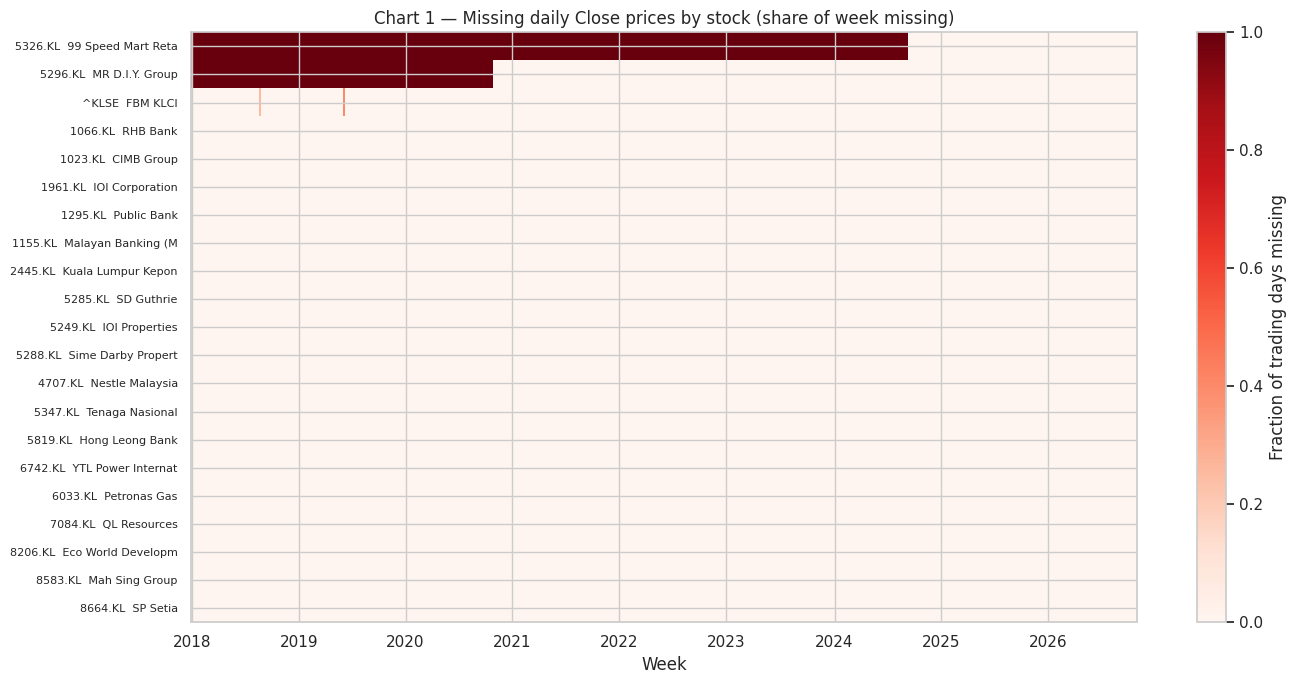

In [12]:
# Chart 1 — missing-value heatmap (share of missing days per week, per ticker)
wk = (full.assign(missing=full["Close"].isna())
          .pivot_table(index="Ticker", columns=pd.Grouper(key="Date", freq="W"), values="missing", aggfunc="mean"))
wk = wk.loc[miss.index]                       # most-missing tickers at the top
labels = [f"{t}  {STOCKS.get(t, ('FBM KLCI',))[0][:18]}" for t in wk.index]

fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(wk.values, aspect="auto", cmap="Reds", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
years = pd.DatetimeIndex(wk.columns)
ticks = [i for i in range(len(years)) if i == 0 or years[i].year != years[i - 1].year]
ax.set_xticks(ticks); ax.set_xticklabels([years[i].year for i in ticks])
ax.set_xlabel("Week"); ax.set_title("Chart 1 — Missing daily Close prices by stock (share of week missing)")
fig.colorbar(im, ax=ax, label="Fraction of trading days missing")
plt.tight_layout(); plt.savefig(FIG / "01_missing_heatmap.png", dpi=150); plt.show()

**What the heatmap shows:** solid red blocks on the left are stocks that **did not exist yet**, because they listed after 2018. Thin red stripes are short gaps such as suspensions or missing Yahoo bars. Long red runs in the middle of a stock's life are longer suspensions.

We classify every missing cell by *why* it is missing, because each cause needs a different fix:

In [13]:
def classify_missing(g):
    g = g.sort_values("Date").copy()
    s = g["Close"]
    status = pd.Series("ok", index=g.index)
    first, last = s.first_valid_index(), s.last_valid_index()
    if first is None:
        g["status"] = "no_data"; return g
    isna = s.isna()
    status[isna] = "gap"
    status[g.index < first] = "pre_listing"
    status[g.index > last] = "after_last_trade"
    gap = status.eq("gap")
    run = (gap != gap.shift()).cumsum()
    run_len = gap.groupby(run).transform("sum")
    status[gap & (run_len <= MAX_FFILL)] = "short_gap"
    status[gap & (run_len > MAX_FFILL)] = "long_gap"
    g["status"] = status
    return g

full = pd.concat([classify_missing(g) for _, g in full.groupby("Ticker")], ignore_index=True)
pd.crosstab(full["Ticker"], full["status"]).loc[miss.index]

status,ok,pre_listing,short_gap
Ticker,,,
5326.KL,526,1636,0
5296.KL,1473,689,0
^KLSE,2159,0,3
1066.KL,2162,0,0
1023.KL,2162,0,0
1961.KL,2162,0,0
1295.KL,2162,0,0
1155.KL,2162,0,0
2445.KL,2162,0,0


In [14]:
# Handling
price_cols = ["Open", "High", "Low", "Close", "Adj_Close"]
short = full["status"].eq("short_gap")
filled = full.groupby("Ticker")[price_cols].ffill()
full.loc[short, price_cols] = filled.loc[short, price_cols]
full.loc[short, "Volume"] = 0
full["flag_imputed"] = short
for c in ["Dividends", "Stock_Splits"]:
    full[c] = full[c].fillna(0)
full["flag_invalid"] = full["flag_invalid"].astype("boolean").fillna(False).astype(bool)

# Zero-volume days that are not imputed: the price shown is stale (no trades happened)
full["flag_no_trade"] = full["status"].eq("ok") & full["Volume"].eq(0)

handled = full["status"].value_counts().rename("cells").to_frame()
handled["action"] = handled.index.map({
    "ok": "keep",
    "short_gap": f"forward-fill price, Volume=0, flag (≤{MAX_FFILL} days)",
    "long_gap": "leave NaN, flag; excluded from event windows",
    "pre_listing": "leave NaN; stock did not exist",
    "after_last_trade": "leave NaN; stock stopped trading / data ends",
    "no_data": "drop ticker",
})
print("Zero-volume (stale price) days flagged:", int(full["flag_no_trade"].sum()))
handled

Zero-volume (stale price) days flagged: 148


,cells,action
status,,
ok,43074,keep
pre_listing,2325,leave NaN; stock did not exist
short_gap,3,"forward-fill price, Volume=0, flag (≤3 days)"


**Reasoning for each decision**

- **Pre-listing (leave NaN):** a company that was not listed has no price. Imputing one would invent history. These stocks are simply excluded from OPR events that happened before they listed.
- **Short gaps ≤ 3 trading days (forward-fill + flag):** the last traded price is the market's best estimate of value, which is standard practice for price series. Volume is set to 0 because no shares changed hands. A flag column is kept so imputed days can be excluded later if needed.
- **Long gaps > 3 days (leave NaN + flag):** usually a trading suspension. Forward-filling a week or more would show a flat price that never existed and would hide the real jump when trading resumes.
- **Zero-volume days:** the price is stale. We keep the row but flag it.
- **No rows dropped for missing values.** Dropping rows would make tickers misalign by date, which breaks the event-window comparison.

### 3.5 Outliers

Outliers are checked on **daily returns**, not price levels. Prices trend over years, so a high price is not unusual in itself, but a sudden ±15% day is.

In [15]:
full = full.sort_values(["Ticker", "Date"]).reset_index(drop=True)
g = full.groupby("Ticker")
full["ret_close"] = g["Close"].transform(lambda s: s / s.shift(1) - 1)
full["ret_adj"]   = g["Adj_Close"].transform(lambda s: s / s.shift(1) - 1)

def iqr_flags(r, k):
    q1, q3 = r.quantile(0.25), r.quantile(0.75)
    return (r < q1 - k * (q3 - q1)) | (r > q3 + k * (q3 - q1))

rg = full.groupby("Ticker")["ret_close"]
full["out_iqr15"] = rg.transform(lambda r: iqr_flags(r, 1.5))
full["out_iqr3"]  = rg.transform(lambda r: iqr_flags(r, 3.0))
full["z"]         = rg.transform(lambda r: (r - r.mean()) / r.std())
full["out_z4"]    = full["z"].abs() > 4

out_tbl = full.groupby("Ticker")[["out_iqr15", "out_iqr3", "out_z4"]].sum()
out_tbl.columns = ["IQR ×1.5", "IQR ×3", "|z| > 4"]
out_tbl["max |return| %"] = (full.groupby("Ticker")["ret_close"].apply(lambda r: r.abs().max()) * 100).round(1)
out_tbl.sort_values("IQR ×3", ascending=False)

,IQR ×1.5,IQR ×3,|z| > 4,max |return| %
Ticker,,,,
4707.KL,231,81,24,10.4
2445.KL,211,50,16,10.5
5819.KL,200,50,16,11.8
1155.KL,186,45,15,12.0
1295.KL,188,44,13,18.6
5347.KL,165,43,15,9.2
8206.KL,140,39,18,21.0
8583.KL,159,36,15,31.2
6033.KL,174,35,15,12.8


**Method comparison:** stock returns have *fat tails*, so the textbook IQR ×1.5 rule flags many normal volatile days. We use **IQR ×3 and |z| > 4** to define "extreme" outliers and investigate each one. That is a manageable number to explain individually.

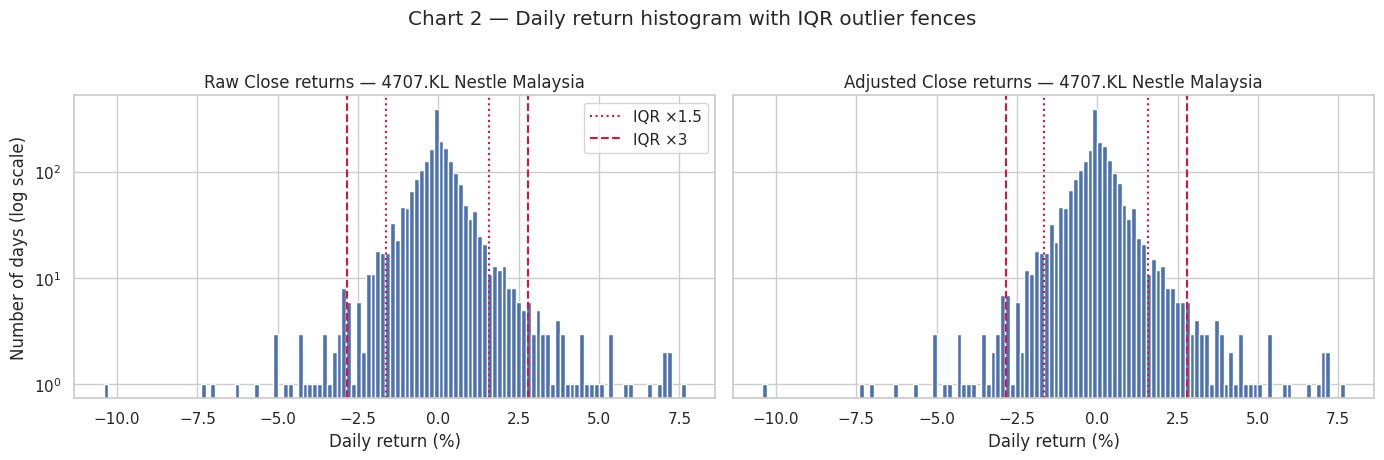

In [16]:
# Chart 2 — return distribution with outlier fences (Close vs Adjusted Close) for one stock
ex = out_tbl["IQR ×3"].idxmax()
sub = full[full["Ticker"] == ex]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, col, ttl in zip(axes, ["ret_close", "ret_adj"], ["Raw Close", "Adjusted Close"]):
    r = sub[col].dropna() * 100
    q1, q3 = r.quantile([.25, .75]); i = q3 - q1
    ax.hist(r, bins=120, color="#4C72B0")
    for f, ls in [(1.5, ":"), (3, "--")]:
        ax.axvline(q1 - f * i, color="crimson", ls=ls); ax.axvline(q3 + f * i, color="crimson", ls=ls, label=f"IQR ×{f}")
    ax.set_yscale("log"); ax.set_xlabel("Daily return (%)"); ax.set_title(f"{ttl} returns — {ex} {STOCKS.get(ex, ('',))[0]}")
axes[0].set_ylabel("Number of days (log scale)"); axes[0].legend()
fig.suptitle("Chart 2 — Daily return histogram with IQR outlier fences", y=1.02)
plt.tight_layout(); plt.savefig(FIG / "02_return_histogram.png", dpi=150, bbox_inches="tight"); plt.show()

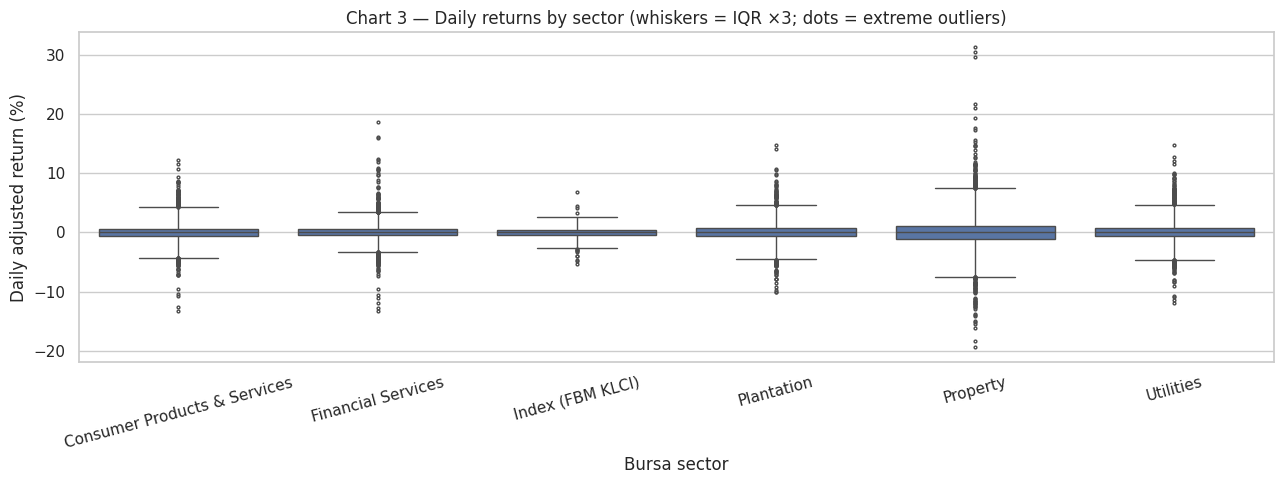

In [17]:
# Chart 3 — boxplots of daily returns by Bursa sector
bp = full.merge(sector_map, on="Ticker", how="left")
bp["bursa_sector"] = bp["bursa_sector"].fillna("Index (FBM KLCI)")
fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=bp, x="bursa_sector", y=bp["ret_adj"] * 100, whis=3, fliersize=2, ax=ax,
            order=sorted(bp["bursa_sector"].unique()))
ax.set_xlabel("Bursa sector"); ax.set_ylabel("Daily adjusted return (%)")
ax.set_title("Chart 3 — Daily returns by sector (whiskers = IQR ×3; dots = extreme outliers)")
plt.xticks(rotation=15); plt.tight_layout(); plt.savefig(FIG / "03_sector_boxplot.png", dpi=150); plt.show()

In [18]:
# Explain every extreme outlier: is it a data artefact or a real market move?
klci = full[full["Ticker"] == INDEX].set_index("Date")["ret_close"]
klci_thr = klci.abs().quantile(0.99)                      # top 1% of index moves = market-wide shock
full["klci_ret"] = full["Date"].map(klci)
full["prev_status"] = full.groupby("Ticker")["status"].shift()

ext = full[(full["out_iqr3"] | full["out_z4"]) & (full["Ticker"] != INDEX)].copy()
ext["cause"] = np.select(
    [ (ext["Dividends"] > 0) | (ext["Stock_Splits"] > 0),
      ext["flag_imputed"] | ext["flag_no_trade"] | ext["prev_status"].eq("long_gap"),
      ext["klci_ret"].abs() >= klci_thr ],
    ["corporate action (dividend/split)", "follows a gap / stale price", "market-wide shock"],
    default="stock-specific news")
print(f"Market-wide threshold: |KLCI return| ≥ {klci_thr*100:.2f}%\n")
print(ext["cause"].value_counts().to_string())
ext[["Date", "Ticker", "Close", "ret_close", "ret_adj", "klci_ret", "Dividends", "cause"]].sort_values("ret_close").head(12)

Market-wide threshold: |KLCI return| ≥ 2.33%

cause
stock-specific news                  505
market-wide shock                    113
corporate action (dividend/split)     37
follows a gap / stale price            4


,Date,Ticker,Close,ret_close,ret_adj,klci_ret,Dividends,cause
41618,2020-03-16,8664.KL,0.815,-0.193069,-0.193069,-0.047682,0.00,market-wide shock
39456,2020-03-16,8583.KL,0.425,-0.182692,-0.182692,-0.047682,0.00,market-wide shock
21069,2024-08-05,5288.KL,1.250,-0.161074,-0.161074,-0.046287,0.00,market-wide shock
540,2020-03-16,1023.KL,3.600,-0.156909,-0.132530,-0.047682,0.12,corporate action (dividend/split)
19557,2018-05-31,5288.KL,1.150,-0.154412,-0.154412,0.012412,0.00,follows a gap / stale price
42697,2024-08-15,8664.KL,1.290,-0.151316,-0.151316,0.000366,0.00,stock-specific news
42706,2024-08-28,8664.KL,1.080,-0.149606,-0.149606,0.013890,0.00,stock-specific news
37294,2020-03-16,8206.KL,0.425,-0.141414,-0.141414,-0.047682,0.00,market-wide shock
42689,2024-08-05,8664.KL,1.240,-0.138889,-0.138889,-0.046287,0.00,market-wide shock
40527,2024-08-05,8583.KL,1.500,-0.137931,-0.137931,-0.046287,0.00,market-wide shock


In [19]:
# Handling
decision = {
    "corporate action (dividend/split)": "FIX — use Adj_Close returns (artefact of the payout, not a price move)",
    "follows a gap / stale price":       "FLAG — return spans several days; exclude from 1-day event stats",
    "market-wide shock":                 "KEEP — genuine (e.g. COVID crash Mar 2020); this is the signal we study",
    "stock-specific news":               "KEEP + FLAG — genuine, but may be unrelated to OPR",
}
print(pd.Series(decision).to_string(), "\n")

full["ret"] = full["ret_adj"]                                     # analysis return
full["flag_outlier"] = full["out_iqr3"] | full["out_z4"]
full["flag_multi_day_ret"] = full["Ticker"].ne(INDEX) & (
    full["flag_imputed"] | full["prev_status"].eq("long_gap"))
# Robustness copy: winsorise each stock at its 1st/99th percentile (do NOT replace the original)
full["ret_winsor"] = full.groupby("Ticker")["ret"].transform(
    lambda r: r.clip(r.quantile(0.01), r.quantile(0.99)))

still = full.groupby("Ticker")["ret"].apply(lambda r: iqr_flags(r, 3).sum()).sum()
print("Extreme outliers on raw Close returns:", int(full["out_iqr3"].sum()))
print("Extreme outliers on Adjusted returns: ", int(still))

corporate action (dividend/split)    FIX — use Adj_Close returns (artefact of the p...
follows a gap / stale price          FLAG — return spans several days; exclude from...
market-wide shock                    KEEP — genuine (e.g. COVID crash Mar 2020); th...
stock-specific news                  KEEP + FLAG — genuine, but may be unrelated to... 

Extreme outliers on raw Close returns: 673
Extreme outliers on Adjusted returns:  646


**Reasoning:** we **do not remove** genuine outliers. The project studies how stocks react to rate news, and the largest moves *are* the reaction. Deleting them would bias the result toward "no effect".

- **Artefacts** (ex-dividend drops, splits) are fixed by using the **adjusted** close.
- **Returns that span a data gap** are flagged, because they are not true one-day moves.
- **Market-wide shocks** such as the March 2020 COVID crash are real. We keep them but will mention that they overlap with the 2020 OPR cuts.
- A **winsorised copy** (`ret_winsor`) is kept only to check whether conclusions still hold without extreme days. Capping the main column would hide real risk.

### 3.6 Inconsistent categories — sector labels

Distinct Bursa sector labels: 5
Distinct Yahoo sector labels: 7 ['Consumer Cyclical', 'Consumer Defensive', 'Energy', 'Financial Services', 'Industrials', 'Real Estate', 'Utilities']
Yahoo sector missing for: none


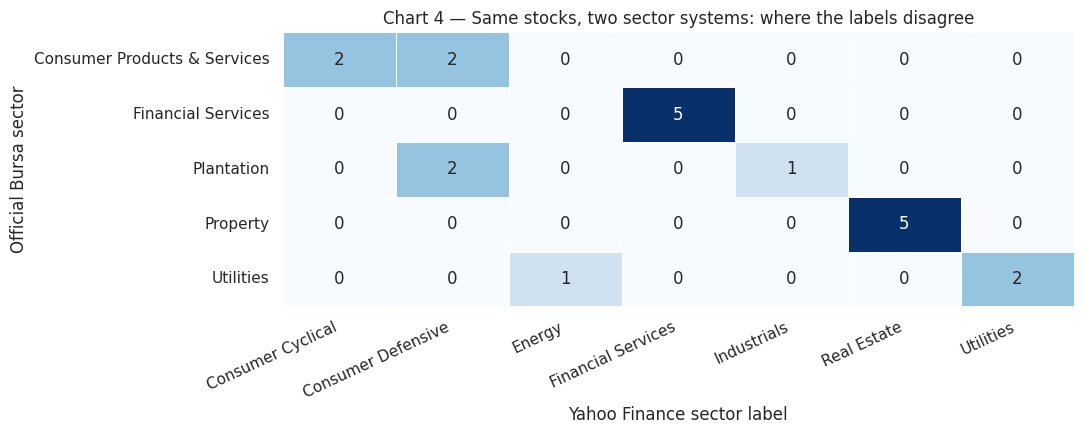

,Ticker,company,bursa_sector,yahoo_sector,yahoo_industry
0,1155.KL,Malayan Banking (Maybank),Financial Services,Financial Services,Banks - Regional
1,1295.KL,Public Bank,Financial Services,Financial Services,Banks - Regional
2,1023.KL,CIMB Group,Financial Services,Financial Services,Banks - Regional
3,1066.KL,RHB Bank,Financial Services,Financial Services,Banks - Regional
4,5819.KL,Hong Leong Bank,Financial Services,Financial Services,Banks - Regional
5,8664.KL,SP Setia,Property,Real Estate,Real Estate - Development
6,5288.KL,Sime Darby Property,Property,Real Estate,Real Estate - Development
7,8583.KL,Mah Sing Group,Property,Real Estate,Real Estate - Development
8,8206.KL,Eco World Development,Property,Real Estate,Real Estate - Development
9,5249.KL,IOI Properties,Property,Real Estate,Real Estate - Development


In [20]:
cat = sector_map.merge(yinfo, on="Ticker", how="left")
cat["yahoo_sector"] = cat["yahoo_sector"].fillna("MISSING").str.strip()
print("Distinct Bursa sector labels:", cat["bursa_sector"].nunique())
print("Distinct Yahoo sector labels:", cat["yahoo_sector"].nunique(), sorted(cat["yahoo_sector"].unique()))
print("Yahoo sector missing for:", cat.loc[cat["yahoo_sector"] == "MISSING", "Ticker"].tolist() or "none")

# Chart 4 — crosstab of the two classification systems
ct = pd.crosstab(cat["bursa_sector"], cat["yahoo_sector"])
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=.5, ax=ax)
ax.set_xlabel("Yahoo Finance sector label"); ax.set_ylabel("Official Bursa sector")
ax.set_title("Chart 4 — Same stocks, two sector systems: where the labels disagree")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.savefig(FIG / "04_sector_crosstab.png", dpi=150); plt.show()
cat[["Ticker", "company", "bursa_sector", "yahoo_sector", "yahoo_industry"]]

**Problem:** Yahoo uses a US-style taxonomy (e.g. "Real Estate", "Consumer Defensive"). Plantation is a Bursa sector that does not exist in Yahoo's system, so plantation companies are spread across other labels. Some Yahoo labels may be missing entirely.

**Decision:** the official **Bursa sector is the single source of truth**. The scenario is about Bursa sectors, and Bursa's list is complete and maintained by the exchange. Yahoo's label is kept only as a reference column.

### 3.7 Aligning OPR events to trading days

In [21]:
cal = pd.Series(calendar)
opr["trading_day"] = opr["announcement"].apply(lambda d: cal[cal >= d].min())
opr["moved_to_next_day"] = opr["trading_day"] != opr["announcement"]
opr["in_data_range"] = opr["trading_day"].notna()
# How many of our stocks actually have a price on each event day?
listed = full[full["status"].isin(["ok", "short_gap"])].groupby("Date")["Ticker"].nunique()
opr["stocks_with_price"] = opr["trading_day"].map(listed).astype("Int64")
opr

,announcement,old_opr,new_opr,change_bps,direction,trading_day,moved_to_next_day,in_data_range,stocks_with_price
0,2018-01-25,3.00,3.25,25,Hike,2018-01-25,False,True,19
1,2019-05-07,3.25,3.00,-25,Cut,2019-05-07,False,True,19
2,2020-01-22,3.00,2.75,-25,Cut,2020-01-22,False,True,19
3,2020-03-03,2.75,2.50,-25,Cut,2020-03-03,False,True,19
4,2020-05-05,2.50,2.00,-50,Cut,2020-05-05,False,True,19
5,2020-07-07,2.00,1.75,-25,Cut,2020-07-07,False,True,19
6,2022-05-11,1.75,2.00,25,Hike,2022-05-11,False,True,20
7,2022-07-06,2.00,2.25,25,Hike,2022-07-06,False,True,20
8,2022-09-08,2.25,2.50,25,Hike,2022-09-08,False,True,20
9,2022-11-03,2.50,2.75,25,Hike,2022-11-03,False,True,20


**Decision:** BNM announces at about 3 pm, while Bursa closes at 5 pm, so the announcement day already contains part of the reaction. Any announcement that falls on a non-trading day is moved to the **next trading day**. `stocks_with_price` shows that early events cover fewer stocks, which matters for the bias discussion.

## 4. Exploratory (Diagnostic) Charts

Charts 1–4 above each expose a data problem: **missing data** (Chart 1), **outliers before and after adjustment** (Charts 2–3), and **inconsistent categories** (Chart 4). Chart 5 below checks **group balance**.

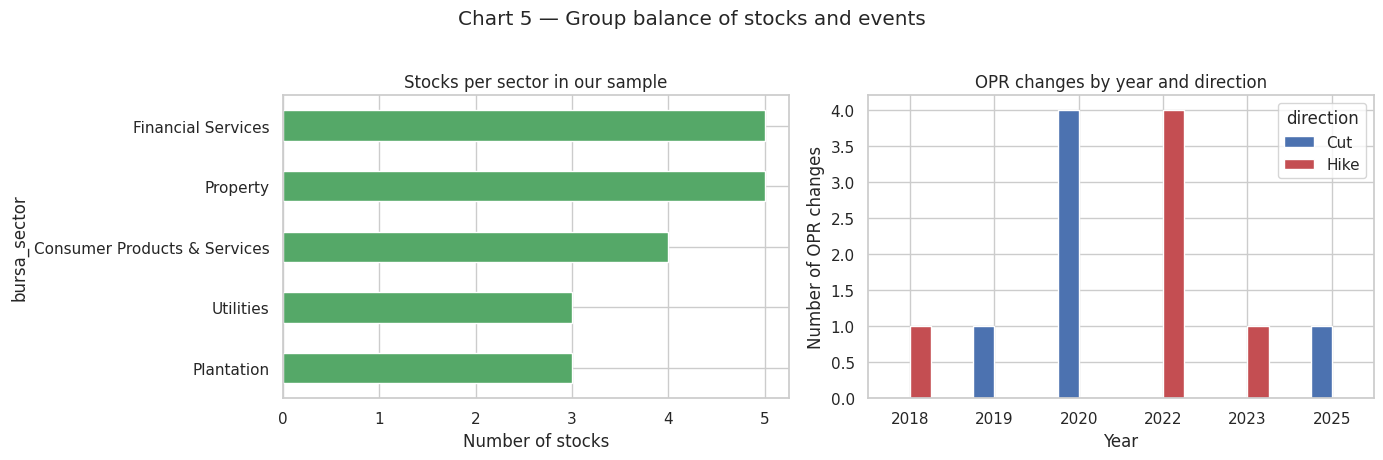

direction
Hike    6
Cut     6


In [22]:
# Chart 5 — group balance: stocks per sector, OPR events by direction and year
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sector_map["bursa_sector"].value_counts().sort_values().plot.barh(ax=axes[0], color="#55A868")
axes[0].set_xlabel("Number of stocks"); axes[0].set_title("Stocks per sector in our sample")

pd.crosstab(opr["announcement"].dt.year, opr["direction"]).plot.bar(ax=axes[1], color={"Cut": "#4C72B0", "Hike": "#C44E52"})
axes[1].set_xlabel("Year"); axes[1].set_ylabel("Number of OPR changes"); axes[1].set_title("OPR changes by year and direction")
axes[1].tick_params(axis="x", rotation=0)
fig.suptitle("Chart 5 — Group balance of stocks and events", y=1.02)
plt.tight_layout(); plt.savefig(FIG / "05_group_balance.png", dpi=150, bbox_inches="tight"); plt.show()
print(opr["direction"].value_counts().to_string())

## 5. PII and Bias Risks

In [23]:
# Automated PII scan over every table's column names and text values
pii_pattern = re.compile(r"(name|email|phone|mobile|ic_?no|nric|passport|address|account|dob|birth)", re.I)
ic_value = re.compile(r"\b\d{6}-\d{2}-\d{4}\b")          # Malaysian MyKad format
email_value = re.compile(r"[\w.]+@[\w.]+\.\w+")
tables = {"prices": full, "yahoo_info": yinfo, "sector_map": sector_map, "opr": opr}
for name, t in tables.items():
    cols = [c for c in t.columns if pii_pattern.search(c)]
    txt = t.select_dtypes(include=["object", "string"]).astype(str)
    hits = int(txt.apply(lambda s: s.str.contains(ic_value) | s.str.contains(email_value)).sum().sum())
    print(f"{name:11s} suspicious column names: {cols or 'none'} | IC/e-mail values found: {hits}")

prices      suspicious column names: none | IC/e-mail values found: 0
yahoo_info  suspicious column names: ['yahoo_name'] | IC/e-mail values found: 0
sector_map  suspicious column names: none | IC/e-mail values found: 0
opr         suspicious column names: none | IC/e-mail values found: 0


In [24]:
# Quantify the bias risks
covid_events = opr["announcement"].between("2020-01-01", "2020-12-31").sum()
late = full[full["status"] == "pre_listing"].groupby("Ticker")["Date"].max().dt.date
print(f"OPR events: {len(opr)}  (hikes {sum(opr.direction=='Hike')}, cuts {sum(opr.direction=='Cut')})")
print(f"Events inside 2020 (COVID year): {covid_events} of {len(opr)}")
print("Stocks missing from early events because they listed later:")
print(late.to_string())
print("\nStocks per sector:\n" + sector_map["bursa_sector"].value_counts().to_string())

OPR events: 12  (hikes 6, cuts 6)
Events inside 2020 (COVID year): 4 of 12
Stocks missing from early events because they listed later:
Ticker
5296.KL    2020-10-23
5326.KL    2024-09-06

Stocks per sector:
bursa_sector
Financial Services              5
Property                        5
Consumer Products & Services    4
Plantation                      3
Utilities                       3


**PII:** the scan finds that the market data contains **no personal data**. It holds only listed companies, prices and official policy rates, all of which are public. The fields `company` and `yahoo_name` match the word "name", but they are corporate names, not people. **If the firm later joins this data with its own client portfolios** (names, MyKad numbers, holdings), those fields would fall under Malaysia's **Personal Data Protection Act 2010**. We would then pseudonymise client IDs with a hash, store only aggregated holdings per sector, and restrict access to the raw client table.

**Bias risks and how we would handle them**

| Risk | Evidence | Handling |
|---|---|---|
| **Survivorship bias** | All 20 stocks are large companies that are still listed in 2026. Companies that collapsed or delisted since 2018 are absent, so sector returns look better than reality. | State it as a limitation; for the capstone, add a few delisted or smaller-cap names, or compare against Bursa's sector indices. |
| **Selection (size) bias** | Only big, liquid blue chips were picked. Small property and plantation firms may react to rates differently. | Report results as "large-cap sectors" only; optionally add a small-cap sample. |
| **Unbalanced groups** | Sectors have 3–5 stocks each (Chart 5); a sector with 3 stocks is driven by any single company. | Use equal-weighted sector averages and report the number of stocks behind each figure. |
| **Unbalanced / clustered events** | Only about 12 rate changes; several cuts fall in 2020, the same year as the COVID crash. | Compare against the KLCI (market-adjusted returns), report 2020 events separately, and avoid claiming cause and effect. |
| **Coverage changes over time** | Stocks that listed late are absent from early events (`stocks_with_price` in 3.7). | Compare sectors only on events where the sector has full coverage. |

## 6. Conclusion

In [25]:
clean = full[full["Ticker"].isin(TICKERS)].copy()
scorecard = pd.Series({
    "raw rows downloaded": len(raw),
    "rows on clean trading grid": len(clean),
    "trading days": len(calendar),
    "duplicate rows removed": int(raw.duplicated(subset=["Date", "Ticker"]).sum()),
    "invalid prices nulled": int(clean["flag_invalid"].sum()),
    "short gaps forward-filled": int(clean["flag_imputed"].sum()),
    "cells left NaN (pre-listing / long gap / ended)": int(clean["Close"].isna().sum()),
    "extreme outliers (raw close)": int(clean["out_iqr3"].sum()),
    "extreme outliers after adjustment": int(clean.groupby("Ticker")["ret"].apply(lambda r: iqr_flags(r, 3).sum()).sum()),
    "OPR events usable": int(opr["in_data_range"].sum()),
})
keep = ["Date", "Ticker", "Open", "High", "Low", "Close", "Adj_Close", "Volume", "Dividends", "Stock_Splits",
        "status", "ret", "ret_winsor", "flag_imputed", "flag_no_trade", "flag_invalid", "flag_outlier", "flag_multi_day_ret"]
clean[keep].merge(sector_map, on="Ticker", how="left").to_csv(PROC / "prices_clean.csv", index=False)
opr.to_csv(PROC / "opr_events_clean.csv", index=False)
print("Saved data/processed/prices_clean.csv and opr_events_clean.csv\n")
scorecard.to_frame("value")

Saved data/processed/prices_clean.csv and opr_events_clean.csv



,value
raw rows downloaded,43083
rows on clean trading grid,45402
trading days,2162
duplicate rows removed,0
invalid prices nulled,0
short gaps forward-filled,3
cells left NaN (pre-listing / long gap / ended),2325
extreme outliers (raw close),673
extreme outliers after adjustment,646
OPR events usable,12


**Is the data fit for the scenario?** **Yes, with conditions.** After cleaning, every stock sits on one Bursa trading calendar. Dates and rates are in proper types, duplicates and impossible values are removed, short gaps are filled and flagged, and dividend artefacts are removed by using adjusted prices. Every remaining missing value has a known cause (not yet listed, suspended, or data ended). The real extreme moves we kept are exactly the reactions the firm wants to measure.

**Remaining limitations**
1. **Small number of events:** about 12 OPR changes is too few for strong statistical claims. Results should be presented as observed patterns, not proof.
2. **Confounding events:** the 2020 cuts overlap the COVID crash, and other news (elections, palm-oil prices, budgets) also moves sectors. Market-adjusted returns reduce but do not remove this.
3. **Survivorship and size bias:** only large stocks that are still listed are included.
4. **Unofficial source:** `yfinance` is not an official Bursa feed. Values can be revised and the API can break, so we keep the raw snapshot with its download date.
5. **Uneven coverage:** stocks that listed late (MR D.I.Y., 99 Speed Mart) cannot contribute to earlier events, which unbalances sector averages across time.

The cleaned files in `data/processed/` will feed the capstone pipeline (warehouse load and event-window analysis).